<a href="https://colab.research.google.com/github/preethikris/BMSCE-DATA-VISUALIZATION/blob/main/lab_program_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100%|██████████| 522M/522M [00:07<00:00, 75.3MB/s]

Extracting files...


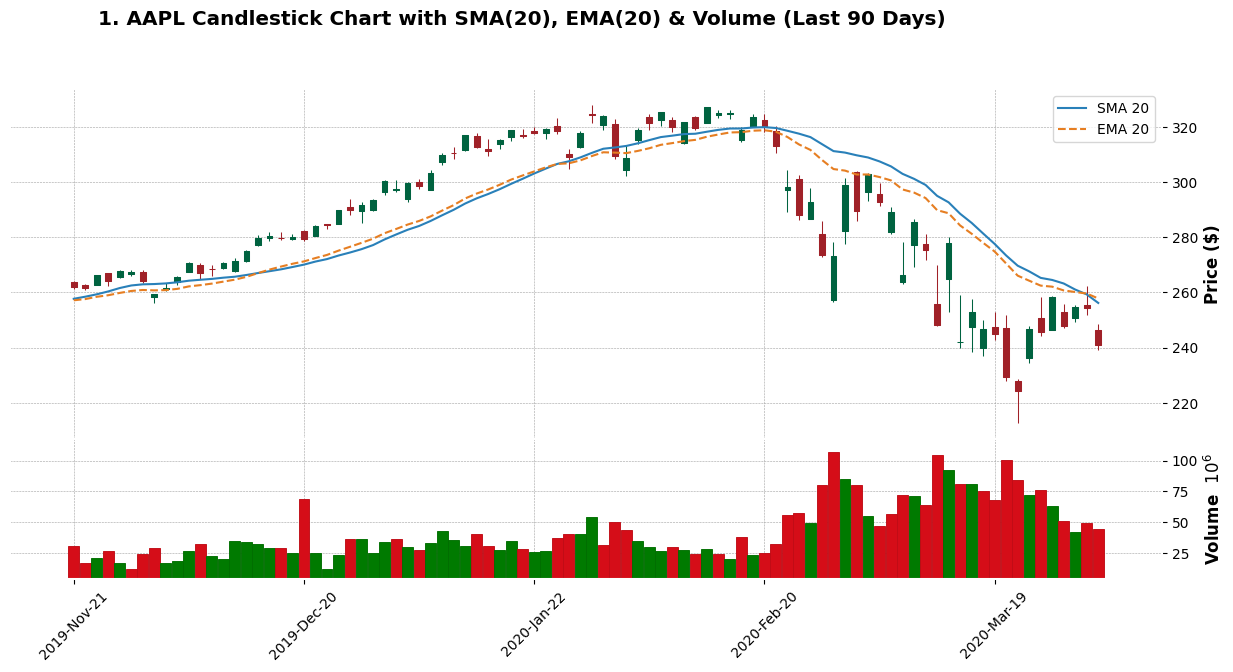

/tmp/ipykernel_880/1360368702.py:86: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Month', y=df['Daily_Return']*100, order=month_order, palette='coolwarm', ax=axes[3])


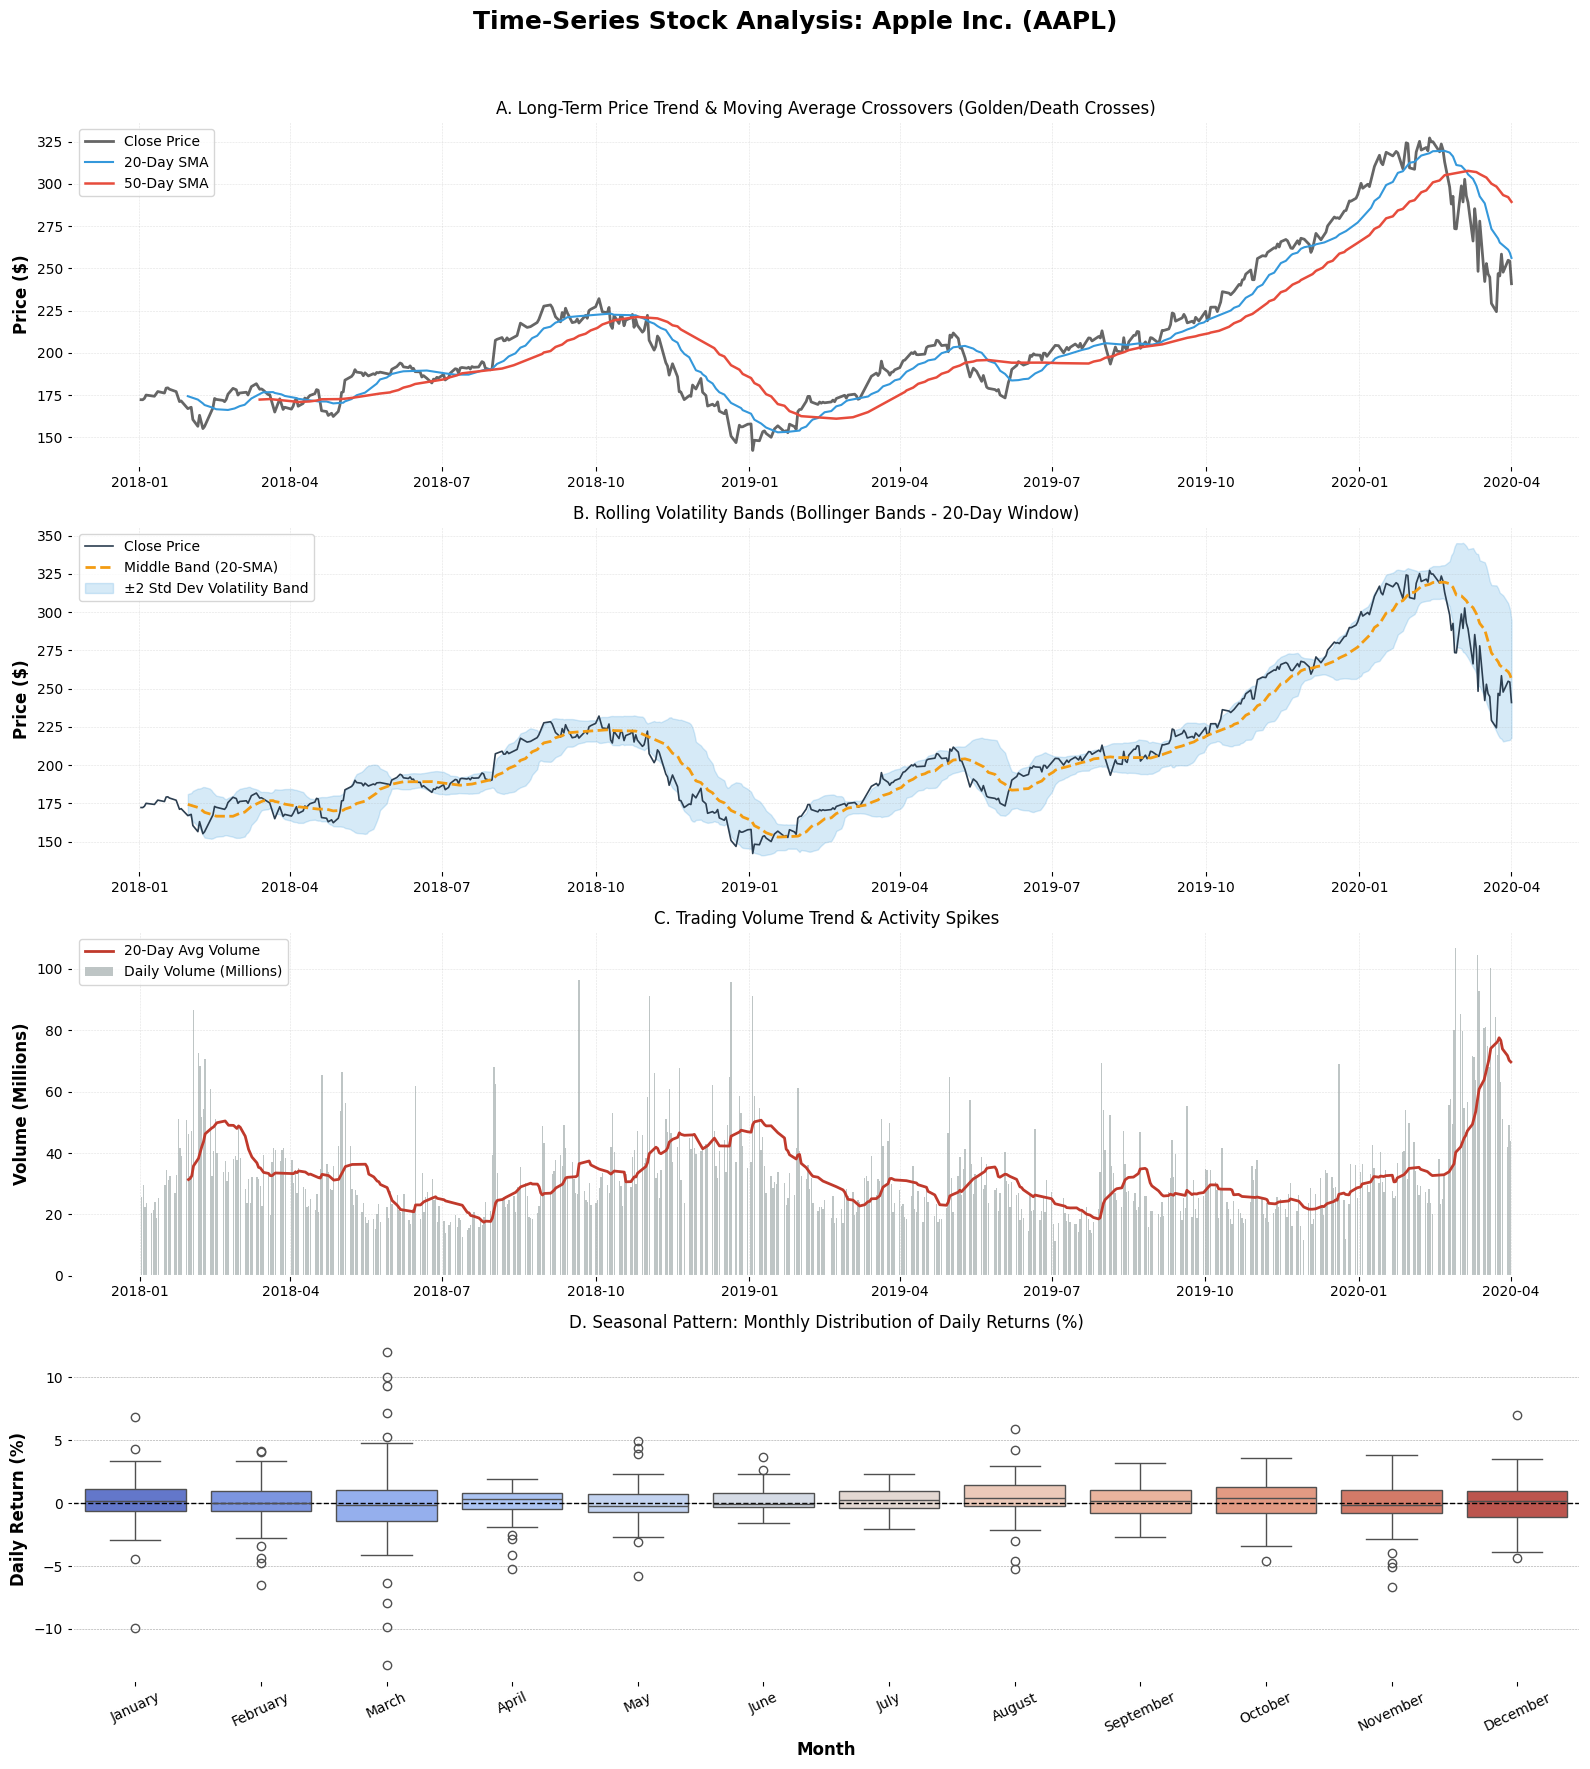

--- AAPL Summary Metrics & Variable Correlations ---
                        Close  Volume  Rolling_Volatility_Pct  Daily_Return
Close                   1.000   0.039                  -0.046         0.057
Volume                  0.039   1.000                   0.552        -0.165
Rolling_Volatility_Pct -0.046   0.552                   1.000        -0.065
Daily_Return            0.057  -0.165                  -0.065         1.000


In [1]:
!pip install -q mplfinance kagglehub

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mplfinance as mpf
import os

# 1. Download Dataset directly via KaggleHub
path = kagglehub.dataset_download("jacksoncrow/stock-market-dataset")
csv_path = os.path.join(path, "stocks", "AAPL.csv")
df = pd.read_csv(csv_path)

# 2. Time-Series Preprocessing & Technical Indicators
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').set_index('Date')
df = df.loc['2018-01-01':'2020-04-01'].copy() # Focus on a clear multi-year window

# Moving Averages (Trend)
df['SMA_20'] = df['Close'].rolling(window=20).mean()
df['SMA_50'] = df['Close'].rolling(window=50).mean()
df['EMA_20'] = df['Close'].ewm(span=20, adjust=False).mean()

# Rolling Volatility & Bollinger Bands (20-day ± 2 Std Dev)
df['Rolling_Std_20'] = df['Close'].rolling(window=20).std()
df['Upper_Band'] = df['SMA_20'] + (2 * df['Rolling_Std_20'])
df['Lower_Band'] = df['SMA_20'] - (2 * df['Rolling_Std_20'])

# Returns & Seasonality Features
df['Daily_Return'] = df['Close'].pct_change()
df['Rolling_Volatility_Pct'] = df['Daily_Return'].rolling(window=20).std() * np.sqrt(252) * 100
df['Month'] = df.index.month_name()

# --- VISUALIZATION 1: Candlestick Chart with SMA, EMA & Volume (Last 90 Trading Days) ---
recent_df = df.tail(90)
apds = [
    mpf.make_addplot(recent_df['SMA_20'], color='#2980b9', width=1.5, label='SMA 20'),
    mpf.make_addplot(recent_df['EMA_20'], color='#e67e22', width=1.5, linestyle='--', label='EMA 20')
]
mpf.plot(
    recent_df,
    type='candle',
    style='charles',
    title='1. AAPL Candlestick Chart with SMA(20), EMA(20) & Volume (Last 90 Days)',
    ylabel='Price ($)',
    volume=True,
    addplot=apds,
    figsize=(16, 7)
)

# --- VISUALIZATION 2: Multi-Panel Time-Series Evaluation ---
fig, axes = plt.subplots(4, 1, figsize=(16, 18))
fig.suptitle('Time-Series Stock Analysis: Apple Inc. (AAPL)', fontsize=18, fontweight='bold', y=0.98)

# Panel A: Long-Term Trend with SMA(20) vs SMA(50) Crossover
axes[0].plot(df.index, df['Close'], label='Close Price', color='black', alpha=0.6)
axes[0].plot(df.index, df['SMA_20'], label='20-Day SMA', color='#3498db', linewidth=1.5)
axes[0].plot(df.index, df['SMA_50'], label='50-Day SMA', color='#e74c3c', linewidth=1.8)
axes[0].set_title('A. Long-Term Price Trend & Moving Average Crossovers (Golden/Death Crosses)')
axes[0].set_ylabel('Price ($)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Panel B: Rolling Volatility Bands (Bollinger Bands)
axes[1].plot(df.index, df['Close'], label='Close Price', color='#2c3e50', linewidth=1.2)
axes[1].plot(df.index, df['SMA_20'], label='Middle Band (20-SMA)', color='#f39c12', linestyle='--')
axes[1].fill_between(df.index, df['Upper_Band'], df['Lower_Band'], color='#3498db', alpha=0.2, label='±2 Std Dev Volatility Band')
axes[1].set_title('B. Rolling Volatility Bands (Bollinger Bands - 20-Day Window)')
axes[1].set_ylabel('Price ($)')
axes[1].legend()
axes[1].grid(alpha=0.3)

# Panel C: Volume Trend & Moving Average Volume
axes[2].bar(df.index, df['Volume'] / 1e6, color='#7f8c8d', alpha=0.5, label='Daily Volume (Millions)')
axes[2].plot(df.index, (df['Volume'] / 1e6).rolling(20).mean(), color='#c0392b', linewidth=2, label='20-Day Avg Volume')
axes[2].set_title('C. Trading Volume Trend & Activity Spikes')
axes[2].set_ylabel('Volume (Millions)')
axes[2].legend()
axes[2].grid(alpha=0.3)

# Panel D: Monthly Seasonality of Daily Returns (Box Plot)
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
sns.boxplot(data=df, x='Month', y=df['Daily_Return']*100, order=month_order, palette='coolwarm', ax=axes[3])
axes[3].axhline(0, color='black', linestyle='--', linewidth=1)
axes[3].set_title('D. Seasonal Pattern: Monthly Distribution of Daily Returns (%)')
axes[3].set_ylabel('Daily Return (%)')
axes[3].tick_params(axis='x', rotation=25)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Print Key Relationships & Variability Metrics
print("--- AAPL Summary Metrics & Variable Correlations ---")
print(df[['Close', 'Volume', 'Rolling_Volatility_Pct', 'Daily_Return']].corr().round(3))